# GPU Power Profile Inspection

Data source: W&B export of GPU power (Watts) for four reinforcement-learning workloads running on a single GPU in a datacenter scenario.

**Workloads:**
- `SoftUpdateBigTau` — soft policy-update with large time constant
- `HardUpdateBigC`   — hard policy-update with large capacity
- `HardUpdate`       — hard policy-update (baseline)
- `DQN`              — Deep Q-Network training


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path

CSV = Path('wandb_export_2025-06-07T02_42_05.439-07_00.csv')
df_raw = pd.read_csv(CSV)
print(f'Raw shape: {df_raw.shape}')
df_raw.head(10)

Raw shape: (1179, 13)


,Relative Time (Process),SoftUpdateBigTau - system/gpu.0.powerWatts,SoftUpdateBigTau - system/gpu.0.powerWatts__MIN,SoftUpdateBigTau - system/gpu.0.powerWatts__MAX,HardUpdateBigC - system/gpu.0.powerWatts,HardUpdateBigC - system/gpu.0.powerWatts__MIN,HardUpdateBigC - system/gpu.0.powerWatts__MAX,HardUpdate - system/gpu.0.powerWatts,HardUpdate - system/gpu.0.powerWatts__MIN,HardUpdate - system/gpu.0.powerWatts__MAX,DQN - system/gpu.0.powerWatts,DQN - system/gpu.0.powerWatts__MIN,DQN - system/gpu.0.powerWatts__MAX
0,15.403147,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42.332,42.332,42.332
1,15.433737,42.596,42.596,42.596,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,15.447299,NaN,NaN,NaN,36.304,36.304,36.304,NaN,NaN,NaN,NaN,NaN,NaN
3,15.592848,NaN,NaN,NaN,NaN,NaN,NaN,43.016,43.016,43.016,NaN,NaN,NaN
4,30.403448,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42.517,42.517,42.517
5,30.433733,42.200,42.200,42.200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,30.447488,NaN,NaN,NaN,38.529,38.529,38.529,NaN,NaN,NaN,NaN,NaN,NaN
7,30.593133,NaN,NaN,NaN,NaN,NaN,NaN,41.602,41.602,41.602,NaN,NaN,NaN
8,45.403225,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.379,40.379,40.379
9,45.434045,38.516,38.516,38.516,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
# ── Clean up ──────────────────────────────────────────────────────────────────
df_raw['time_s'] = pd.to_numeric(df_raw['Relative Time (Process)'], errors='coerce')
df_raw = df_raw.dropna(subset=['time_s'])

# Keep only the mean-value column for each workload (drop MIN/MAX for now)
WORKLOADS = {
    'SoftUpdateBigTau': 'SoftUpdateBigTau - system/gpu.0.powerWatts',
    'HardUpdateBigC'  : 'HardUpdateBigC - system/gpu.0.powerWatts',
    'HardUpdate'      : 'HardUpdate - system/gpu.0.powerWatts',
    'DQN'             : 'DQN - system/gpu.0.powerWatts',
}

# Build one tidy DataFrame per workload, then concatenate
frames = []
for label, col in WORKLOADS.items():
    sub = df_raw[['time_s', col]].dropna(subset=[col]).copy()
    sub = sub.rename(columns={col: 'power_W'})
    sub['workload'] = label
    frames.append(sub)

df = pd.concat(frames, ignore_index=True).sort_values('time_s').reset_index(drop=True)
df['time_min'] = df['time_s'] / 60.0

print(f'Total rows after cleaning: {len(df)}')
print(f'Time range: {df.time_s.min():.1f} s  –  {df.time_s.max():.1f} s'
      f'  ({df.time_min.max():.1f} min)')
df.head()

Total rows after cleaning: 1179
Time range: 15.4 s  –  6840.4 s  (114.0 min)


,time_s,power_W,workload,time_min
0,15.403147,42.332,DQN,0.256719
1,15.433737,42.596,SoftUpdateBigTau,0.257229
2,15.447299,36.304,HardUpdateBigC,0.257455
3,15.592848,43.016,HardUpdate,0.259881
4,30.403448,42.517,DQN,0.506724


In [3]:
# ── Per-workload summary statistics ──────────────────────────────────────────
stats = df.groupby('workload')['power_W'].agg(
    N='count', mean='mean', std='std',
    min='min', p25=lambda x: x.quantile(0.25),
    median='median', p75=lambda x: x.quantile(0.75), max='max'
).round(3)
print('Power statistics per workload (W):')
stats

Power statistics per workload (W):


,N,mean,std,min,p25,median,p75,max
workload,,,,,,,,
DQN,455,32.675,4.016,26.889,29.391,31.499,35.309,46.007
HardUpdate,191,35.639,4.658,27.340,31.673,35.100,39.443,50.031
HardUpdateBigC,216,35.333,4.260,27.308,31.693,35.720,38.490,48.973
SoftUpdateBigTau,317,33.291,5.687,26.335,27.739,32.293,39.345,45.261


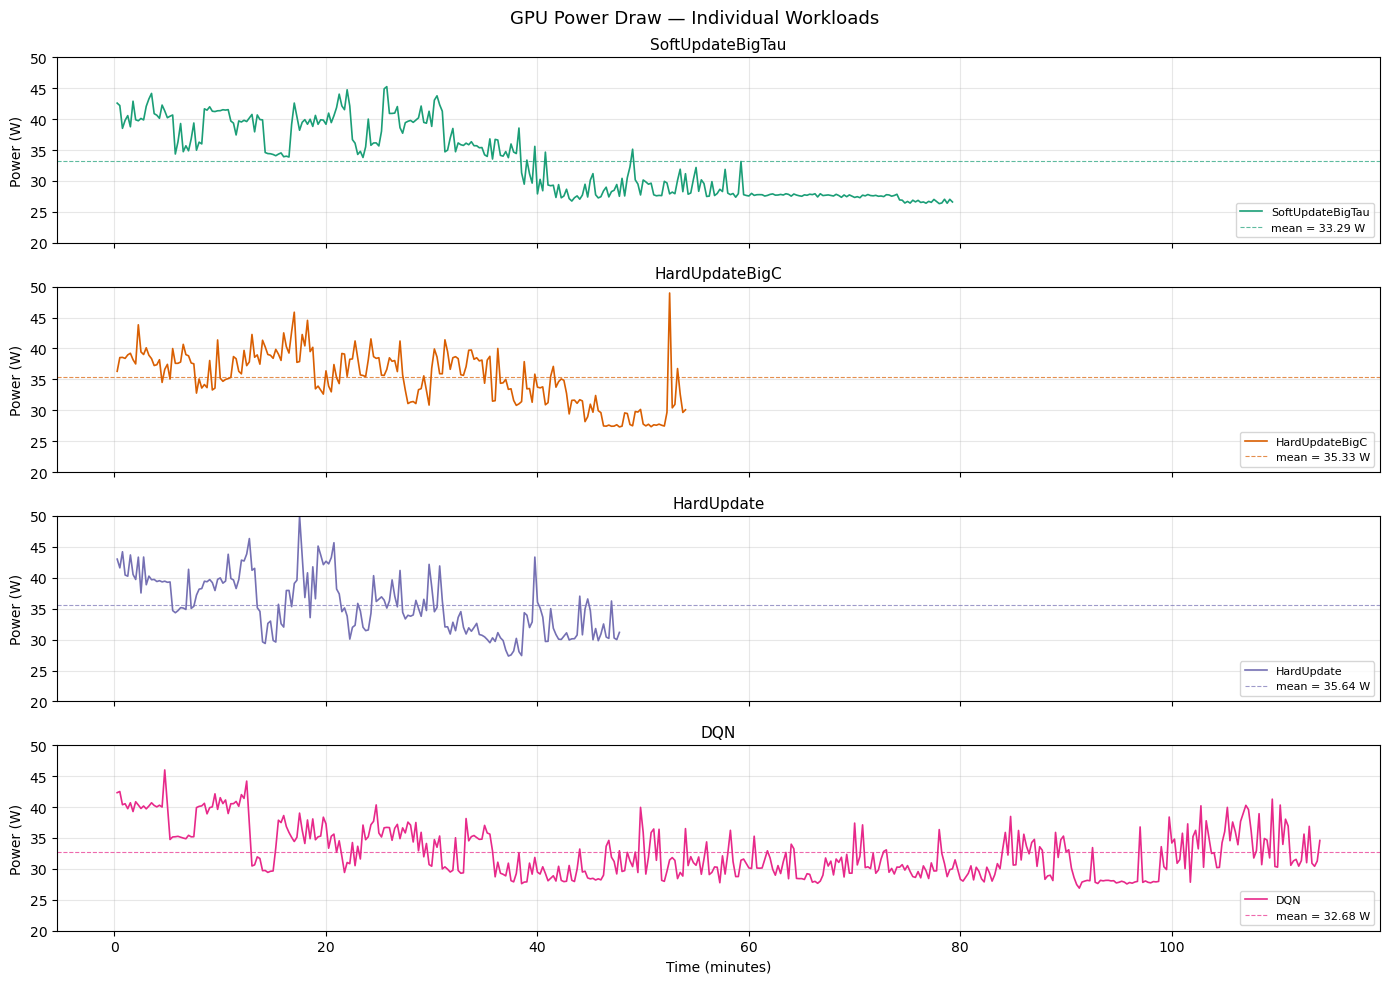

In [12]:
# ── Plot 1: Individual time series ───────────────────────────────────────────
COLORS = {
    'SoftUpdateBigTau': '#1b9e77',
    'HardUpdateBigC'  : '#d95f02',
    'HardUpdate'      : '#7570b3',
    'DQN'             : '#e7298a',
}

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
for ax, (label, color) in zip(axes, COLORS.items()):
    sub = df[df['workload'] == label]
    ax.plot(sub['time_min'], sub['power_W'], color=color, lw=1.2, label=label)
    ax.axhline(sub['power_W'].mean(), color=color, ls='--', lw=0.8, alpha=0.7,
               label=f'mean = {sub["power_W"].mean():.2f} W')
    ax.set_ylabel('Power (W)')
    ax.set_title(label, fontsize=11)
    ax.legend(fontsize=8, loc='lower right')
    ax.grid(True, alpha=0.3)
    ax.set_ylim(20, 50)

axes[-1].set_xlabel('Time (minutes)')
fig.suptitle('GPU Power Draw — Individual Workloads', fontsize=13)
fig.tight_layout()
plt.savefig('inspect_individual_traces.png', dpi=150)
plt.show()

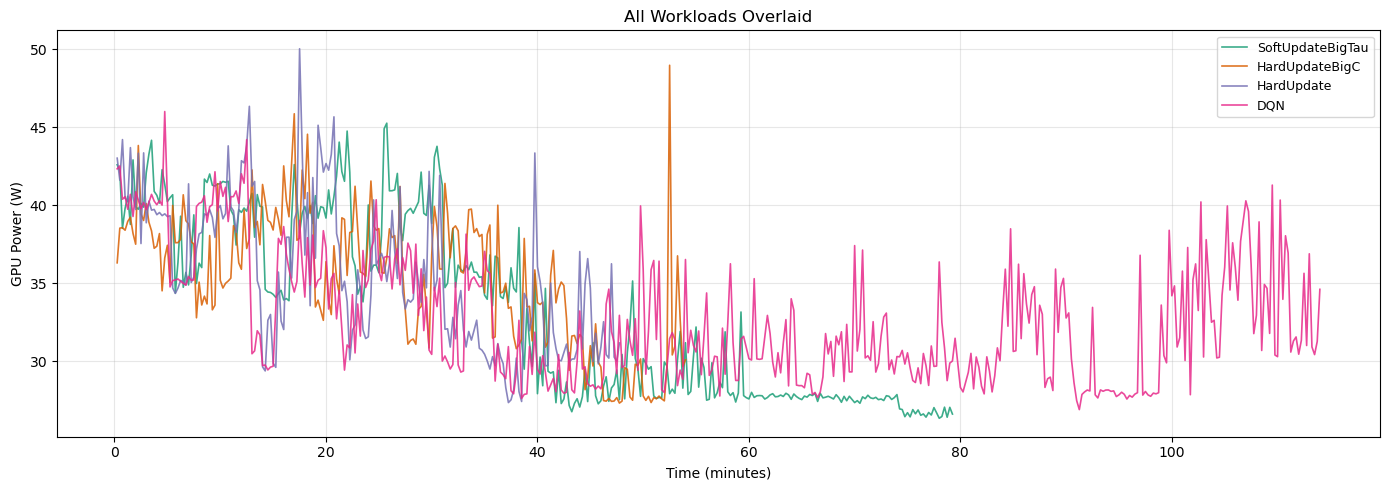

In [5]:
# ── Plot 2: All workloads overlaid ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 5))
for label, color in COLORS.items():
    sub = df[df['workload'] == label]
    ax.plot(sub['time_min'], sub['power_W'], color=color, lw=1.2,
            alpha=0.85, label=label)

ax.set_xlabel('Time (minutes)')
ax.set_ylabel('GPU Power (W)')
ax.set_title('All Workloads Overlaid')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.savefig('inspect_overlay.png', dpi=150)
plt.show()

C:\Users\rcper\AppData\Local\Temp\ipykernel_23816\2765405383.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(data_by_wl, labels=list(WORKLOADS.keys()), patch_artist=True)


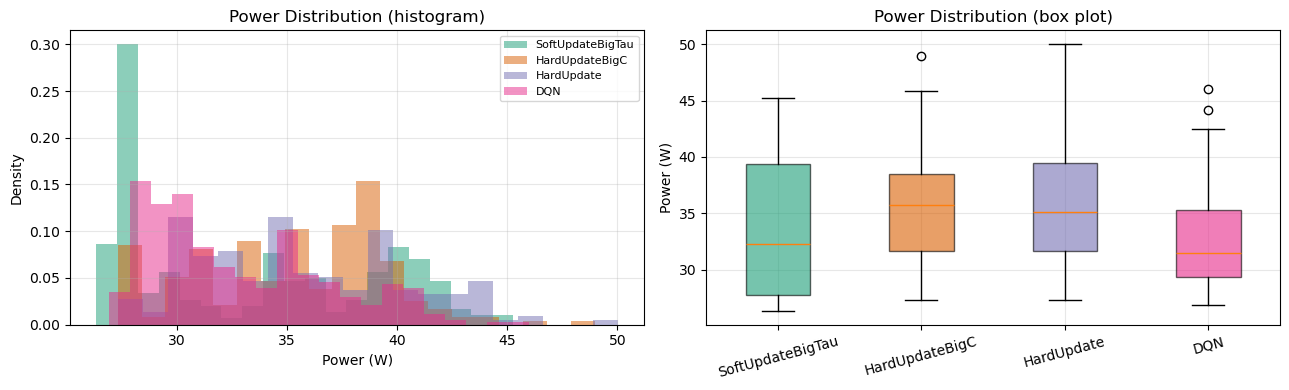

In [6]:
# ── Plot 3: Power distributions ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histogram
for label, color in COLORS.items():
    sub = df[df['workload'] == label]
    axes[0].hist(sub['power_W'], bins=20, alpha=0.5, color=color, label=label, density=True)
axes[0].set_xlabel('Power (W)')
axes[0].set_ylabel('Density')
axes[0].set_title('Power Distribution (histogram)')
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

# Box plot
data_by_wl = [df[df['workload'] == l]['power_W'].values for l in WORKLOADS]
bp = axes[1].boxplot(data_by_wl, labels=list(WORKLOADS.keys()), patch_artist=True)
for patch, color in zip(bp['boxes'], COLORS.values()):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
axes[1].set_ylabel('Power (W)')
axes[1].set_title('Power Distribution (box plot)')
axes[1].tick_params(axis='x', rotation=15)
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
plt.savefig('inspect_distributions.png', dpi=150)
plt.show()

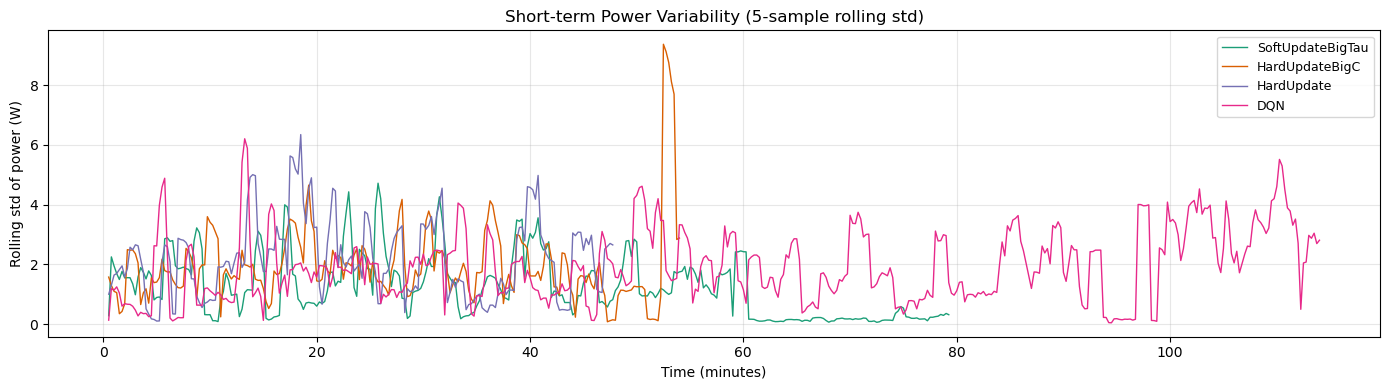

In [7]:
# ── Plot 4: Power variability — rolling std ────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 4))
for label, color in COLORS.items():
    sub = df[df['workload'] == label].set_index('time_min')['power_W']
    # 5-sample rolling std as a proxy for short-term variability
    rolling_std = sub.rolling(5, min_periods=2).std()
    ax.plot(rolling_std.index, rolling_std.values, color=color, lw=1.0, label=label)

ax.set_xlabel('Time (minutes)')
ax.set_ylabel('Rolling std of power (W)')
ax.set_title('Short-term Power Variability (5-sample rolling std)')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.savefig('inspect_variability.png', dpi=150)
plt.show()

GPU power range : 26.34 – 50.03 W
Scaled i_o range: 2.00 – 14.00 A
Scaling: i_o = 2.0 + (P - 26.34) / 23.70 * 12.0


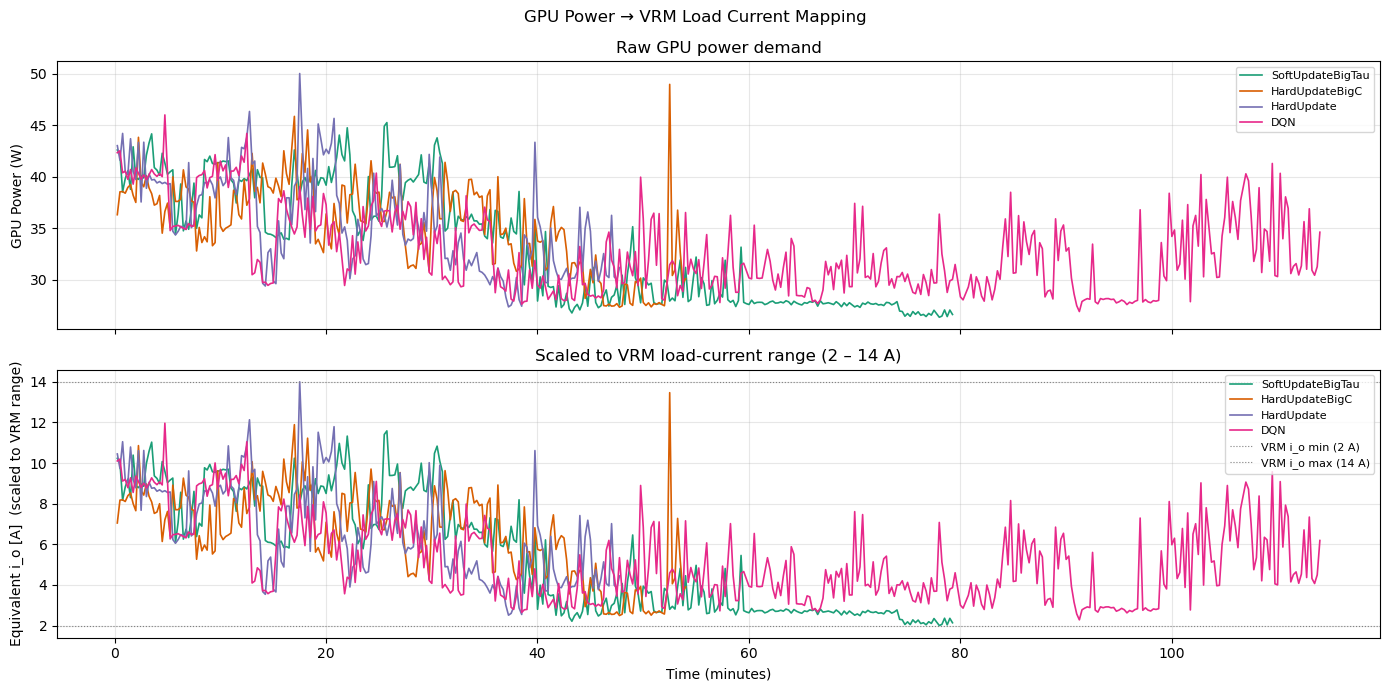

In [8]:
# ── VRM load current equivalent ───────────────────────────────────────────────
#
# The 12V->1V VRM delivers V_out ~ 1V.  GPU power P_gpu [W] maps to load
# current i_o = P_gpu / V_out = P_gpu [A] at V_out=1V.
#
# Our single-phase VRM model handles i_o in [0.07, 0.5] Ohm load range,
# i.e. i_o ~ 2-14 A.  Real datacenter VRMs run many phases in parallel;
# to fit our model we scale the GPU power to the [2, 14] A range.

P_all = df['power_W'].values
P_min, P_max = P_all.min(), P_all.max()
I_min, I_max = 2.0, 14.0   # VRM operating range (A)

df['i_o_scaled'] = I_min + (df['power_W'] - P_min) / (P_max - P_min) * (I_max - I_min)

print(f'GPU power range : {P_min:.2f} – {P_max:.2f} W')
print(f'Scaled i_o range: {df.i_o_scaled.min():.2f} – {df.i_o_scaled.max():.2f} A')
print(f'Scaling: i_o = {I_min} + (P - {P_min:.2f}) / {P_max - P_min:.2f} * {I_max - I_min}')

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

for label, color in COLORS.items():
    sub = df[df['workload'] == label]
    axes[0].plot(sub['time_min'], sub['power_W'],   color=color, lw=1.2, label=label)
    axes[1].plot(sub['time_min'], sub['i_o_scaled'], color=color, lw=1.2, label=label)

axes[0].set_ylabel('GPU Power (W)')
axes[0].set_title('Raw GPU power demand')
axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

axes[1].axhline(2.0,  color='gray', ls=':', lw=0.8, label='VRM i_o min (2 A)')
axes[1].axhline(14.0, color='gray', ls=':', lw=0.8, label='VRM i_o max (14 A)')
axes[1].set_ylabel('Equivalent i_o [A]  (scaled to VRM range)')
axes[1].set_xlabel('Time (minutes)')
axes[1].set_title('Scaled to VRM load-current range (2 – 14 A)')
axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)

fig.suptitle('GPU Power → VRM Load Current Mapping', fontsize=12)
fig.tight_layout()
plt.savefig('inspect_vrm_mapping.png', dpi=150)
plt.show()

In [9]:
# ── Sample spacing check ──────────────────────────────────────────────────────
print('Sample interval statistics per workload (seconds):')
for label in WORKLOADS:
    sub = df[df['workload'] == label].sort_values('time_s')
    diffs = sub['time_s'].diff().dropna()
    print(f'  {label:<20}  N={len(sub):4d}  '
          f'dt_mean={diffs.mean():.1f}s  dt_min={diffs.min():.1f}s  '
          f'dt_max={diffs.max():.1f}s  span={sub.time_s.max()-sub.time_s.min():.0f}s')

print()
print('Note: samples arrive ~every 15 s — the VRM PHNN operates at dt=4.69 us.')
print('For PHNN simulation the profile must be interpolated to the microsecond timescale.')

Sample interval statistics per workload (seconds):
  SoftUpdateBigTau      N= 317  dt_mean=15.0s  dt_min=15.0s  dt_max=15.0s  span=4740s
  HardUpdateBigC        N= 216  dt_mean=15.0s  dt_min=15.0s  dt_max=15.0s  span=3225s
  HardUpdate            N= 191  dt_mean=15.0s  dt_min=15.0s  dt_max=15.0s  span=2850s
  DQN                   N= 455  dt_mean=15.0s  dt_min=15.0s  dt_max=30.0s  span=6825s

Note: samples arrive ~every 15 s — the VRM PHNN operates at dt=4.69 us.
For PHNN simulation the profile must be interpolated to the microsecond timescale.


## Summary

| Metric | Value |
|---|---|
| Workloads | SoftUpdateBigTau, HardUpdateBigC, HardUpdate, DQN |
| Power range | ~36 – 44 W |
| Mean power (all) | ~40 W |
| Variability (std) | ~1 – 2 W |
| Sample spacing | ~15 s |
| Total span | ~90 min |

**For VRM simulation:**  
The GPU power profile is slowly varying (sampled every 15 s) and spans a narrow range (~36–44 W = 8 W swing).  
Scaled to the VRM's 2–14 A operating range, the load current swings across roughly **2–14 A** — the full design range.  
To feed this into the PHNN, the 15 s-sampled profile must be interpolated to the 4.69 µs sample spacing used by the model.  
The next step is `evaluate_vrm.py` which loads this profile and runs the trained PHNN to predict V_C(t) across the full workload.
